# Data Understanding - Phishing Website Detector

**Projeto:** Deteção de Websites de Phishing através de Machine Learning  
**Autor:** Diogo Carvalho  
**Data:** Setembro 2026

Este notebook executa a Análise Exploratória de Dados (EDA) sobre o dataset `phishing.csv`, seguindo a metodologia CRISP-ML(Q).

**Objetivos:**
- Compreender a estrutura e dimensão do dataset
- Analisar a distribuição das classes
- Verificar valores em falta e duplicados
- Analisar a distribuição de cada feature
- Avaliar correlações entre features e com a variável alvo
- Identificar features constantes e pares altamente correlacionados
- Avaliar o desequilíbrio de categorias por feature

## 1. Importação de bibliotecas e carregamento dos dados

In [1]:
import sys
from pathlib import Path

# Adicionar a pasta src ao path
sys.path.insert(0, str(Path("..") / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_utils import (
    carregar_dataset,
    resumo_geral,
    distribuicao_classes,
    valores_unicos,
    variaveis_constantes,
    verificar_padrao_valores,
    distribuicao_features_categoricas,
    graficos_barras_features,
    analise_bivariada,
    graficos_bivariados,
    correlacao_pearson,
    correlacao_spearman,
    matriz_correlacao,
    grafico_correlacao_alvo,
    pares_altamente_correlacionados,
    desequilibrio_categorias,
)

# Configuração de visualização
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")

## 2. Carregamento do dataset

In [2]:
df = carregar_dataset("phishing.csv")

Dataset carregado: 11054 registos × 32 colunas


## 3. Resumo geral do dataset

In [3]:
resumo_geral(df)

RESUMO GERAL DO DATASET

Dimensão: 11054 registos × 32 colunas

Colunas: ['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon', 'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL', 'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick', 'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage', 'StatsReport', 'class']

--- TIPOS DE DADOS ---
Index                  int64
UsingIP                int64
LongURL                int64
ShortURL               int64
Symbol@                int64
Redirecting//          int64
PrefixSuffix-          int64
SubDomains             int64
HTTPS                  int64
DomainRegLen           int64
Favicon                int64
NonStdPort             int64
HTTPSDomainURL         int64
RequestURL             int64
Anchor

## 4. Distribuição das classes

In [4]:
distribuicao_classes(df, target="class")

DISTRIBUIÇÃO DAS CLASSES

Contagem absoluta:
class
 1    6157
-1    4897
Name: count, dtype: int64

Distribuição percentual:
class
 1    55.7
-1    44.3
Name: proportion, dtype: float64


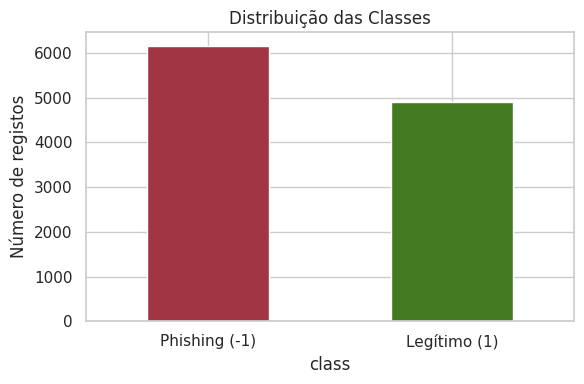

In [5]:
# Gráfico da distribuição das classes
plt.figure(figsize=(6, 4))
df["class"].value_counts().plot(kind="bar", color=["#A13544", "#437A22"])
plt.title("Distribuição das Classes")
plt.xticks([0, 1], ["Phishing (-1)", "Legítimo (1)"], rotation=0)
plt.ylabel("Número de registos")
plt.tight_layout()
plt.show()

## 5. Valores únicos por coluna

In [6]:
valores_unicos(df, drop_cols=["Index"])

NÚMERO DE VALORES ÚNICOS POR COLUNA
UsingIP                2
LongURL                3
ShortURL               2
Symbol@                2
Redirecting//          2
PrefixSuffix-          2
SubDomains             3
HTTPS                  3
DomainRegLen           2
Favicon                2
NonStdPort             2
HTTPSDomainURL         2
RequestURL             2
AnchorURL              3
LinksInScriptTags      3
ServerFormHandler      3
InfoEmail              2
AbnormalURL            2
WebsiteForwarding      2
StatusBarCust          2
DisableRightClick      2
UsingPopupWindow       2
IframeRedirection      2
AgeofDomain            2
DNSRecording           2
WebsiteTraffic         3
PageRank               2
GoogleIndex            2
LinksPointingToPage    3
StatsReport            2
class                  2
dtype: int64


## 6. Variáveis constantes

In [7]:
variaveis_constantes(df, drop_cols=["Index", "class"])

VARIÁVEIS CONSTANTES
Nenhuma variável constante encontrada


[]

## 7. Verificação do padrão de valores (-1, 0, 1)

In [8]:
verificar_padrao_valores(df, target="class", drop_cols=["Index"])

FEATURES COM VALORES FORA DO PADRÃO (-1, 0, 1)
  UsingIP: [np.int64(-1), np.int64(1)]
  ShortURL: [np.int64(-1), np.int64(1)]
  Symbol@: [np.int64(-1), np.int64(1)]
  Redirecting//: [np.int64(-1), np.int64(1)]
  PrefixSuffix-: [np.int64(-1), np.int64(1)]
  DomainRegLen: [np.int64(-1), np.int64(1)]
  Favicon: [np.int64(-1), np.int64(1)]
  NonStdPort: [np.int64(-1), np.int64(1)]
  HTTPSDomainURL: [np.int64(-1), np.int64(1)]
  RequestURL: [np.int64(-1), np.int64(1)]
  InfoEmail: [np.int64(-1), np.int64(1)]
  AbnormalURL: [np.int64(-1), np.int64(1)]
  WebsiteForwarding: [np.int64(0), np.int64(1)]
  StatusBarCust: [np.int64(-1), np.int64(1)]
  DisableRightClick: [np.int64(-1), np.int64(1)]
  UsingPopupWindow: [np.int64(-1), np.int64(1)]
  IframeRedirection: [np.int64(-1), np.int64(1)]
  AgeofDomain: [np.int64(-1), np.int64(1)]
  DNSRecording: [np.int64(-1), np.int64(1)]
  PageRank: [np.int64(-1), np.int64(1)]
  GoogleIndex: [np.int64(-1), np.int64(1)]
  StatsReport: [np.int64(-1), np.int64(

## 8. Distribuição percentual de cada feature

Análise da proporção de cada categoria (-1, 0, 1) em cada feature.

In [9]:
distribuicao_features_categoricas(df, drop_cols=["Index"])

DISTRIBUIÇÃO PERCENTUAL DE CADA FEATURE

--- UsingIP ---
UsingIP
-1    34.3
 1    65.7
Name: proportion, dtype: float64

--- LongURL ---
LongURL
-1    81.06
 0     1.22
 1    17.72
Name: proportion, dtype: float64

--- ShortURL ---
ShortURL
-1    13.06
 1    86.94
Name: proportion, dtype: float64

--- Symbol@ ---
Symbol@
-1    14.97
 1    85.03
Name: proportion, dtype: float64

--- Redirecting// ---
Redirecting//
-1    12.92
 1    87.08
Name: proportion, dtype: float64

--- PrefixSuffix- ---
PrefixSuffix-
-1    86.75
 1    13.25
Name: proportion, dtype: float64

--- SubDomains ---
SubDomains
-1    30.41
 0    32.77
 1    36.82
Name: proportion, dtype: float64

--- HTTPS ---
HTTPS
-1    32.17
 0    10.56
 1    57.27
Name: proportion, dtype: float64

--- DomainRegLen ---
DomainRegLen
-1    66.84
 1    33.16
Name: proportion, dtype: float64

--- Favicon ---
Favicon
-1    18.57
 1    81.43
Name: proportion, dtype: float64

--- NonStdPort ---
NonStdPort
-1    13.59
 1    86.41
Name: proport

## 9. Gráficos de barras das features

Features selecionadas com base na correlação inicial de Pearson com a variável alvo.

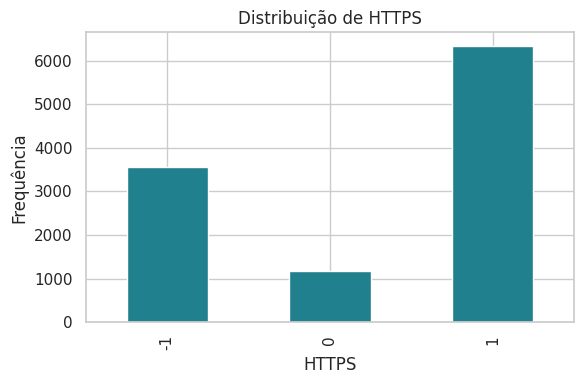

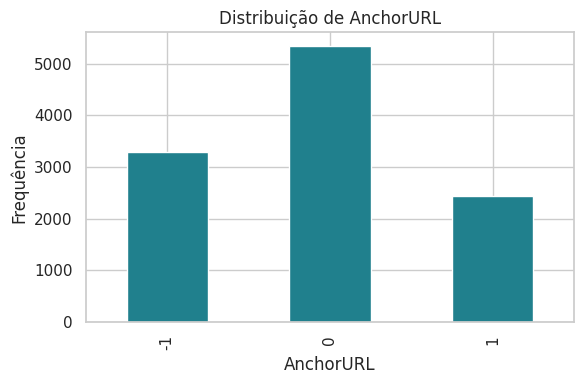

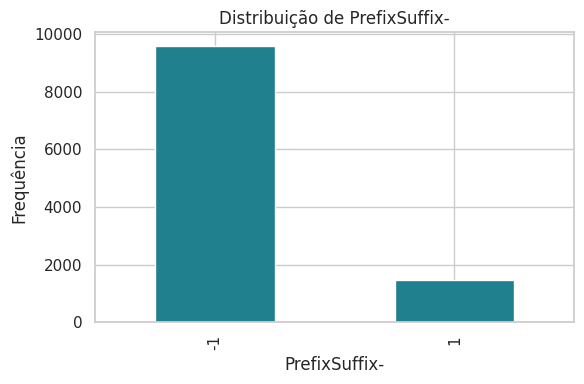

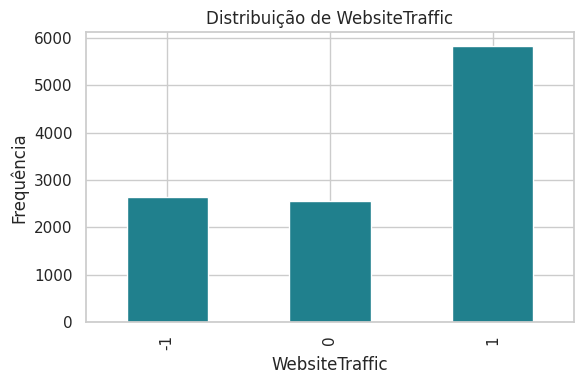

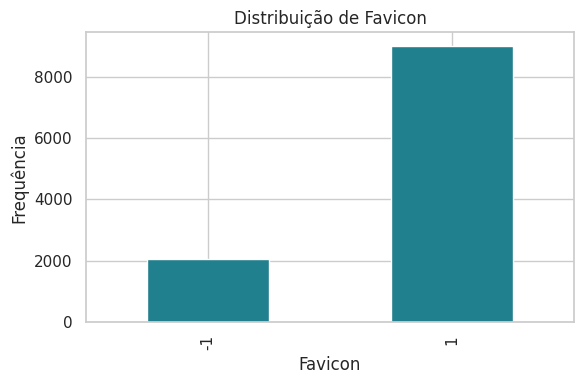

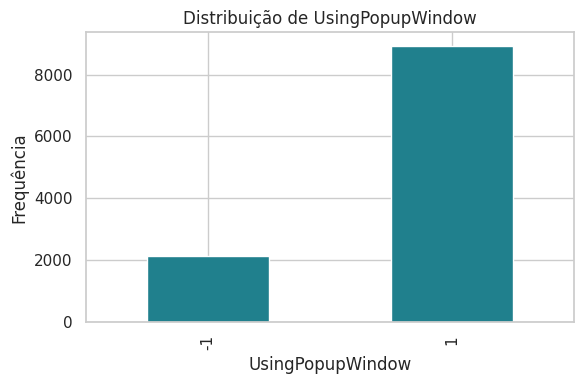

In [10]:
features_destaque = [
    "HTTPS",
    "AnchorURL",
    "PrefixSuffix-",
    "WebsiteTraffic",
    "Favicon",
    "UsingPopupWindow"
]
graficos_barras_features(df, features=features_destaque)

## 10. Análise bivariada: feature por classe

In [11]:
analise_bivariada(df, features=features_destaque)

ANÁLISE BIVARIADA: FEATURE POR CLASSE

--- HTTPS POR CLASSE ---
class         -1          1
HTTPS                      
-1     62.283030   8.218288
 0     23.402083   0.341075
 1     14.314887  91.440637

--- AnchorURL POR CLASSE ---
class            -1          1
AnchorURL                     
-1         66.26506   0.584700
 0         30.67184  62.286828
 1          3.06310  37.128472

--- PrefixSuffix- POR CLASSE ---
class             -1          1
PrefixSuffix-                  
-1             100.0  76.205944
 1               0.0  23.794056

--- WebsiteTraffic POR CLASSE ---
class                  -1          1
WebsiteTraffic                      
-1              34.143353  15.949326
 0              35.082704  13.821666
 1              30.773943  70.229008

--- Favicon POR CLASSE ---
class           -1          1
Favicon                      
-1       18.562385  18.580478
 1       81.437615  81.419522

--- UsingPopupWindow POR CLASSE ---
class                   -1          1
UsingP

## 11. Gráficos de barras agrupados por classe

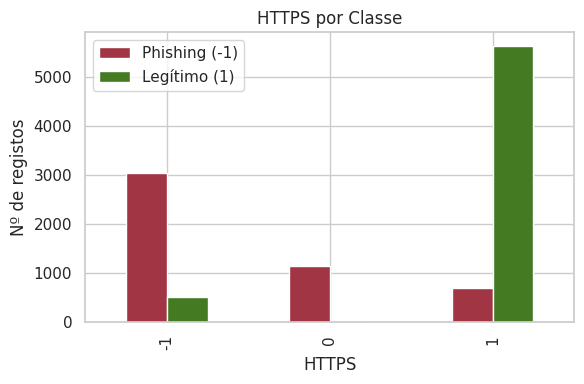

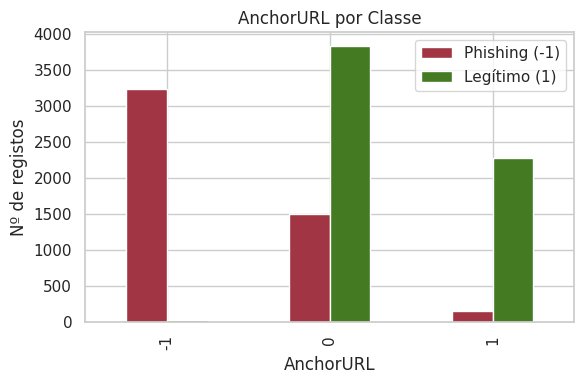

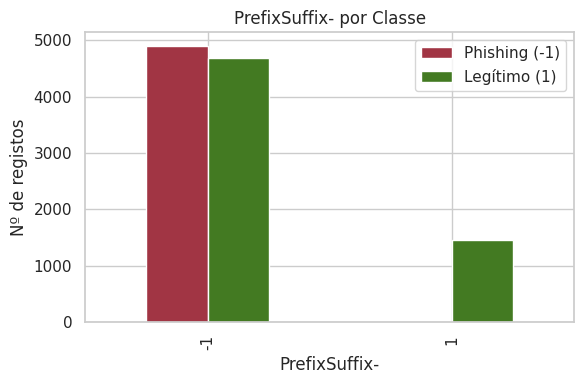

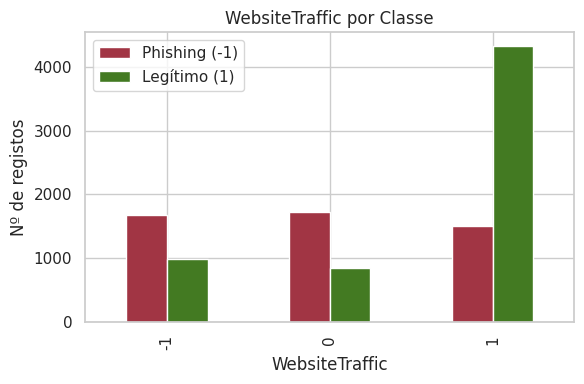

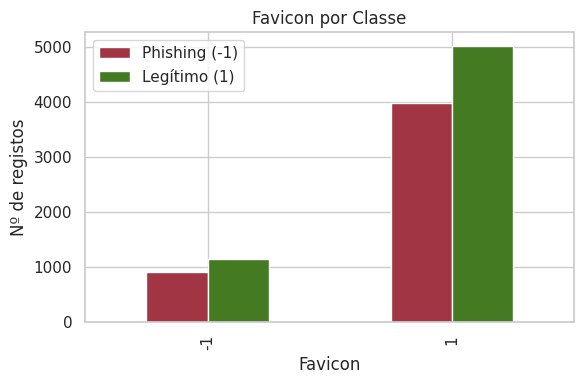

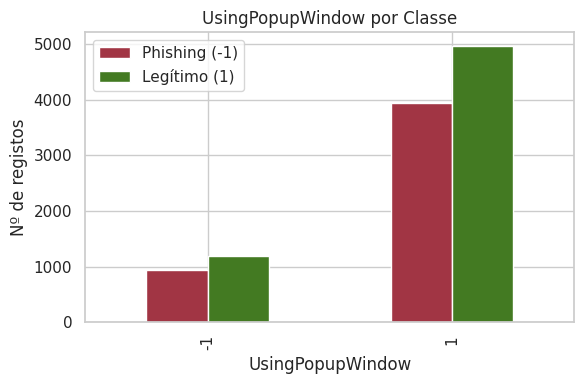

In [12]:
graficos_bivariados(df, features=features_destaque)

## 12. Correlação de Pearson com a variável alvo

In [13]:
corr_pearson = correlacao_pearson(df, target="class", drop_cols=["Index"])

CORRELAÇÃO DE PEARSON COM A VARIÁVEL ALVO
class                  1.0000
HTTPS                  0.7147
AnchorURL              0.6929
PrefixSuffix-          0.3486
WebsiteTraffic         0.3460
SubDomains             0.2982
RequestURL             0.2535
LinksInScriptTags      0.2484
ServerFormHandler      0.2214
GoogleIndex            0.1290
AgeofDomain            0.1214
PageRank               0.1046
UsingIP                0.0940
StatsReport            0.0796
DNSRecording           0.0756
LongURL                0.0577
Symbol@                0.0530
StatusBarCust          0.0419
NonStdPort             0.0365
LinksPointingToPage    0.0327
InfoEmail              0.0180
DisableRightClick      0.0127
UsingPopupWindow       0.0001
Favicon               -0.0002
IframeRedirection     -0.0034
WebsiteForwarding     -0.0202
Redirecting//         -0.0389
HTTPSDomainURL        -0.0401
AbnormalURL           -0.0608
ShortURL              -0.0679
DomainRegLen          -0.2259
Name: class, dtype: float64


## 13. Correlação de Spearman com a variável alvo

In [14]:
corr_spearman = correlacao_spearman(df, target="class", drop_cols=["Index"])

CORRELAÇÃO DE SPEARMAN COM A VARIÁVEL ALVO
class                  1.0000
HTTPS                  0.7358
AnchorURL              0.7012
WebsiteTraffic         0.3650
PrefixSuffix-          0.3486
SubDomains             0.3046
RequestURL             0.2535
LinksInScriptTags      0.2509
ServerFormHandler      0.2191
GoogleIndex            0.1290
AgeofDomain            0.1214
PageRank               0.1046
UsingIP                0.0940
StatsReport            0.0796
DNSRecording           0.0756
LongURL                0.0536
Symbol@                0.0530
StatusBarCust          0.0419
LinksPointingToPage    0.0412
NonStdPort             0.0365
InfoEmail              0.0180
DisableRightClick      0.0127
UsingPopupWindow       0.0001
Favicon               -0.0002
IframeRedirection     -0.0034
WebsiteForwarding     -0.0202
Redirecting//         -0.0389
HTTPSDomainURL        -0.0401
AbnormalURL           -0.0608
ShortURL              -0.0679
DomainRegLen          -0.2259
Name: class, dtype: float64

## 14. Gráfico de correlação com a variável alvo (Pearson)

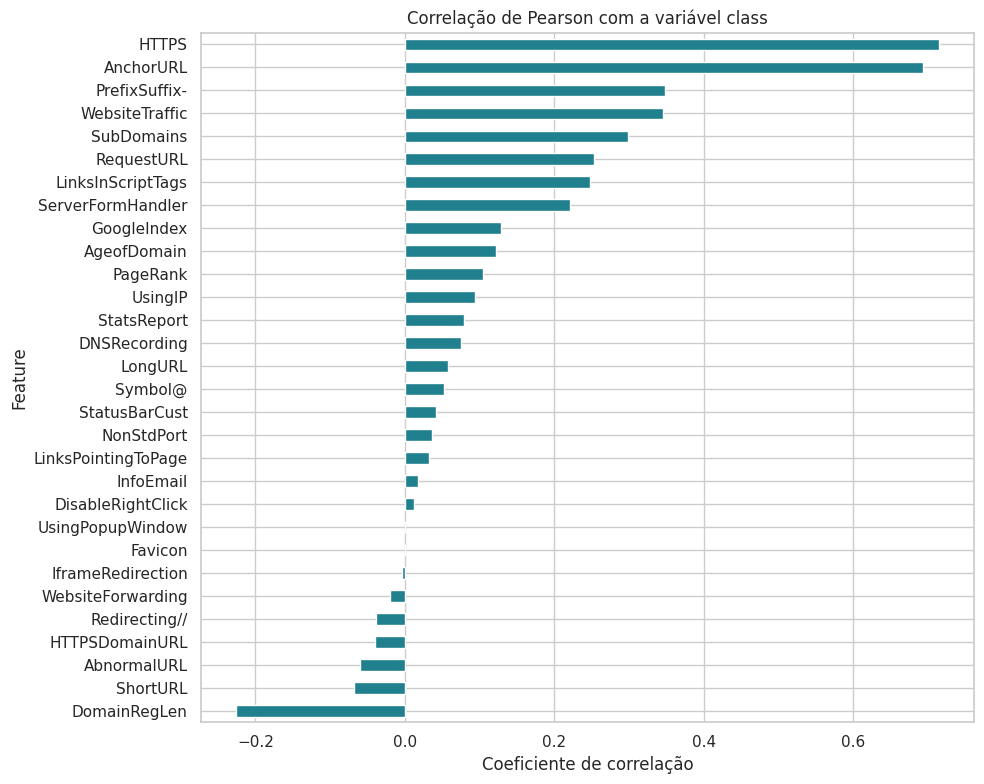

DomainRegLen          -0.225879
ShortURL              -0.067931
AbnormalURL           -0.060751
HTTPSDomainURL        -0.040096
Redirecting//         -0.038885
WebsiteForwarding     -0.020151
IframeRedirection     -0.003362
Favicon               -0.000231
UsingPopupWindow       0.000136
DisableRightClick      0.012675
InfoEmail              0.018039
LinksPointingToPage    0.032694
NonStdPort             0.036461
StatusBarCust          0.041878
Symbol@                0.052994
LongURL                0.057661
DNSRecording           0.075579
StatsReport            0.079632
UsingIP                0.094033
PageRank               0.104593
AgeofDomain            0.121402
GoogleIndex            0.129000
ServerFormHandler      0.221380
LinksInScriptTags      0.248415
RequestURL             0.253478
SubDomains             0.298231
WebsiteTraffic         0.346003
PrefixSuffix-          0.348588
AnchorURL              0.692895
HTTPS                  0.714704
Name: class, dtype: float64

In [15]:
grafico_correlacao_alvo(df, method="pearson", target="class", drop_cols=["Index"])

## 15. Gráfico de correlação com a variável alvo (Spearman)

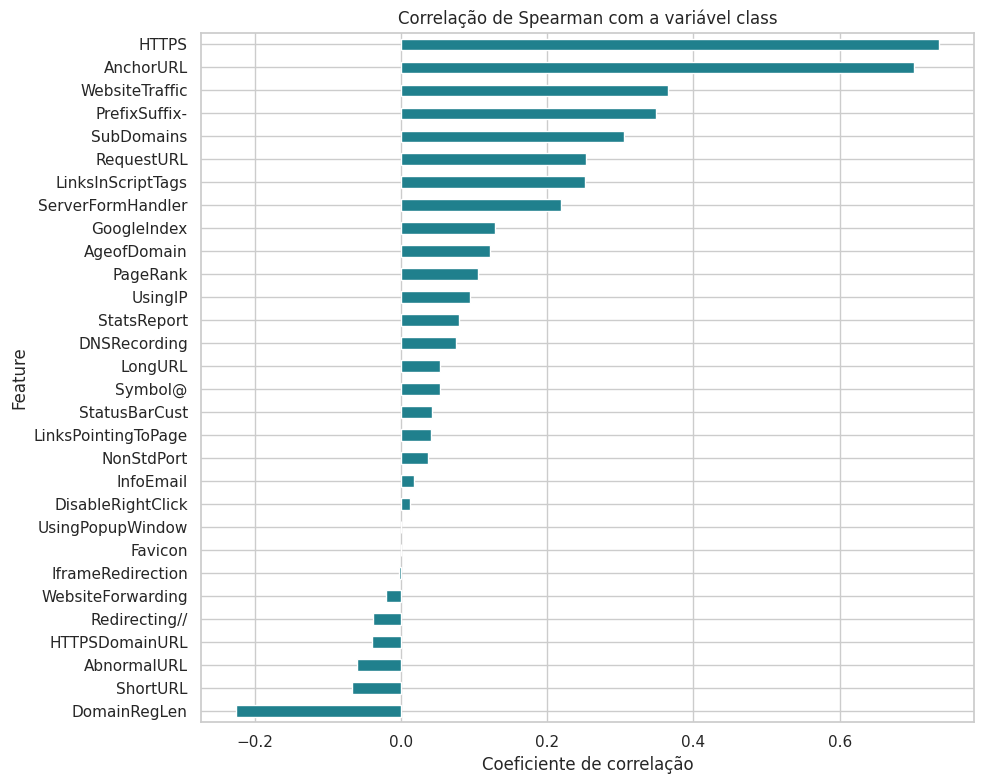

DomainRegLen          -0.225879
ShortURL              -0.067931
AbnormalURL           -0.060751
HTTPSDomainURL        -0.040096
Redirecting//         -0.038885
WebsiteForwarding     -0.020151
IframeRedirection     -0.003362
Favicon               -0.000231
UsingPopupWindow       0.000136
DisableRightClick      0.012675
InfoEmail              0.018039
NonStdPort             0.036461
LinksPointingToPage    0.041210
StatusBarCust          0.041878
Symbol@                0.052994
LongURL                0.053557
DNSRecording           0.075579
StatsReport            0.079632
UsingIP                0.094033
PageRank               0.104593
AgeofDomain            0.121402
GoogleIndex            0.129000
ServerFormHandler      0.219150
LinksInScriptTags      0.250893
RequestURL             0.253478
SubDomains             0.304612
PrefixSuffix-          0.348588
WebsiteTraffic         0.365033
AnchorURL              0.701160
HTTPS                  0.735788
Name: class, dtype: float64

In [16]:
grafico_correlacao_alvo(df, method="spearman", target="class", drop_cols=["Index"])

## 16. Matriz de correlação (Pearson)

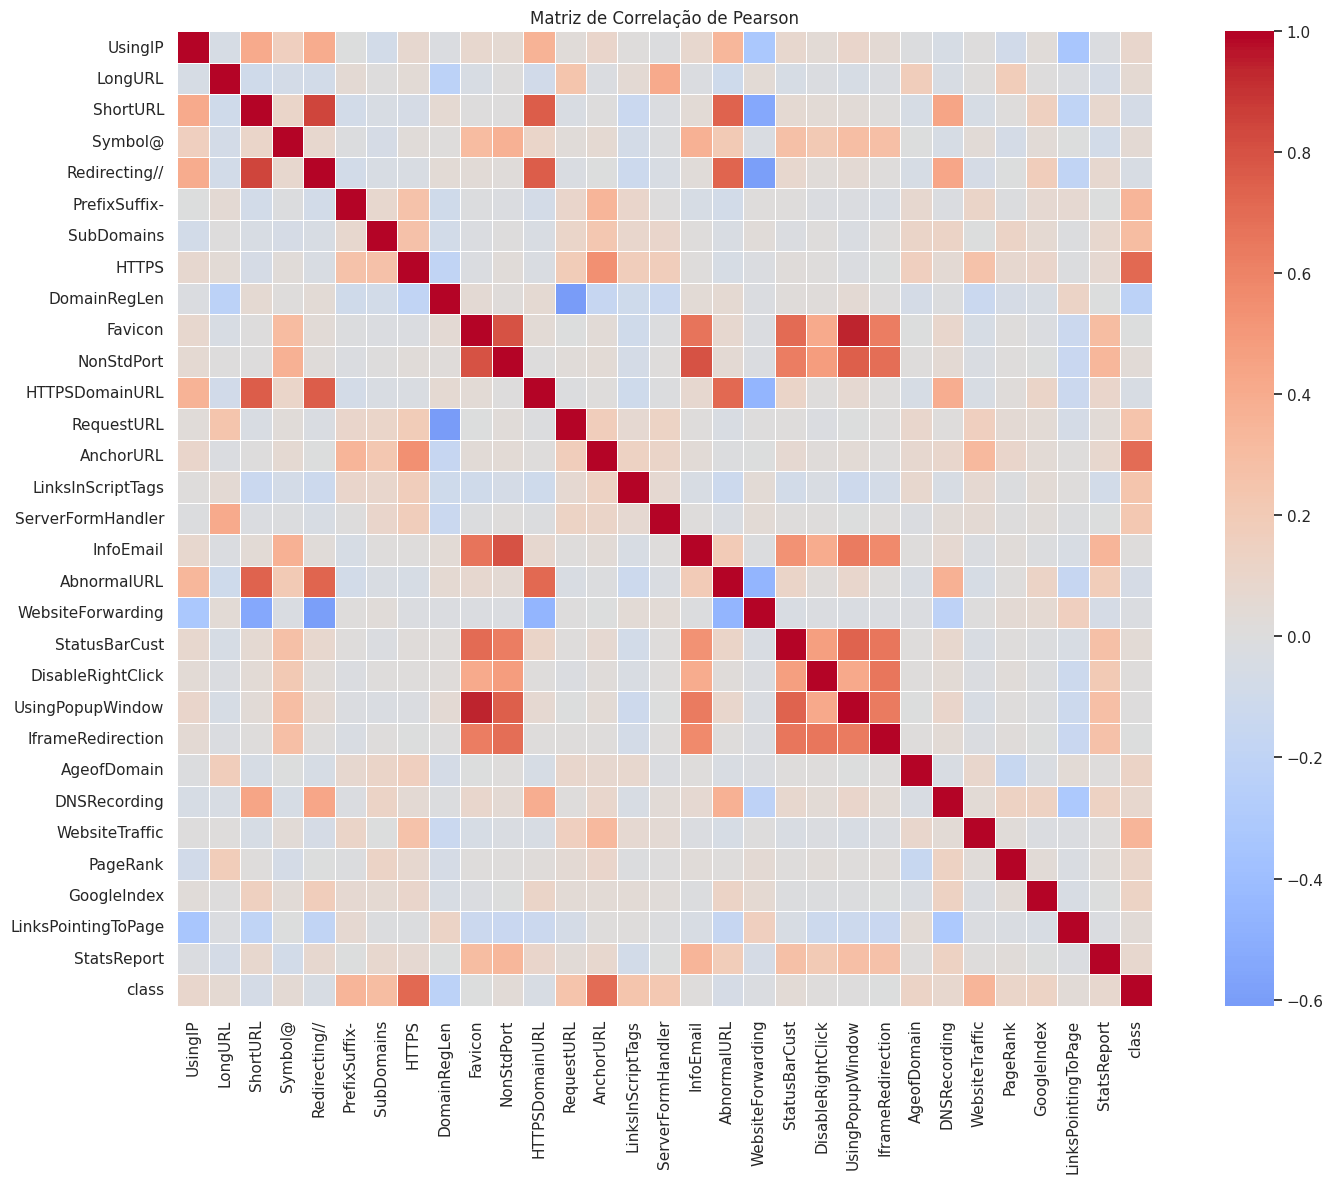

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
UsingIP,1.000000,-0.052159,0.403547,0.158766,0.397220,-0.005306,-0.080921,0.071255,-0.022830,0.087093,...,0.096953,0.054739,-0.010580,-0.050929,0.002728,-0.091857,0.029206,-0.338971,-0.019420,0.094033
LongURL,-0.052159,1.000000,-0.097976,-0.075205,-0.080788,0.055334,0.004249,0.049033,-0.221807,-0.042599,...,-0.049486,-0.013902,0.179678,-0.040549,0.009296,0.183672,0.002825,-0.023216,-0.066708,0.057661
ShortURL,0.403547,-0.097976,1.000000,0.104433,0.843149,-0.080458,-0.041874,-0.061383,0.060950,0.006084,...,0.036599,0.016570,-0.052562,0.436163,-0.047025,0.014612,0.155832,-0.198463,0.085572,-0.067931
Symbol@,0.158766,-0.075205,0.104433,1.000000,0.087086,-0.011711,-0.058931,0.031275,0.015549,0.304887,...,0.290880,0.284401,-0.005459,-0.047820,0.032981,-0.064714,0.037047,-0.006124,-0.080286,0.052994
Redirecting//,0.397220,-0.080788,0.843149,0.087086,1.000000,-0.085709,-0.043401,-0.036536,0.047314,0.035223,...,0.054595,0.010536,-0.050374,0.431235,-0.062761,-0.003272,0.178565,-0.193965,0.069849,-0.038885
PrefixSuffix-,-0.005306,0.055334,-0.080458,-0.011711,-0.085709,1.000000,0.087852,0.261366,-0.096826,-0.007487,...,-0.014716,-0.036894,0.074083,-0.016610,0.110555,-0.006855,0.067796,0.067469,-0.002851,0.348588
SubDomains,-0.080921,0.004249,-0.041874,-0.058931,-0.043401,0.087852,1.000000,0.267531,-0.082930,-0.016650,...,-0.025257,0.010675,0.119144,0.125340,-0.005948,0.120672,0.057725,-0.010392,0.081365,0.298231
HTTPS,0.071255,0.049033,-0.061383,0.031275,-0.036536,0.261366,0.267531,1.000000,-0.193730,-0.014699,...,-0.012945,-0.002734,0.162700,0.050797,0.258625,0.074479,0.096110,-0.011569,0.063126,0.714704
DomainRegLen,-0.022830,-0.221807,0.060950,0.015549,0.047314,-0.096826,-0.082930,-0.193730,1.000000,0.054286,...,0.051443,0.004414,-0.062924,-0.010573,-0.134571,-0.059938,-0.039741,0.122755,-0.002371,-0.225879
Favicon,0.087093,-0.042599,0.006084,0.304887,0.035223,-0.007487,-0.016650,-0.014699,0.054286,1.000000,...,0.939632,0.627603,-0.002582,0.088285,-0.050861,0.011725,-0.016685,-0.127302,0.301111,-0.000231


In [17]:
matriz_correlacao(df, method="pearson", target="class", drop_cols=["Index"])

## 17. Matriz de correlação (Spearman)

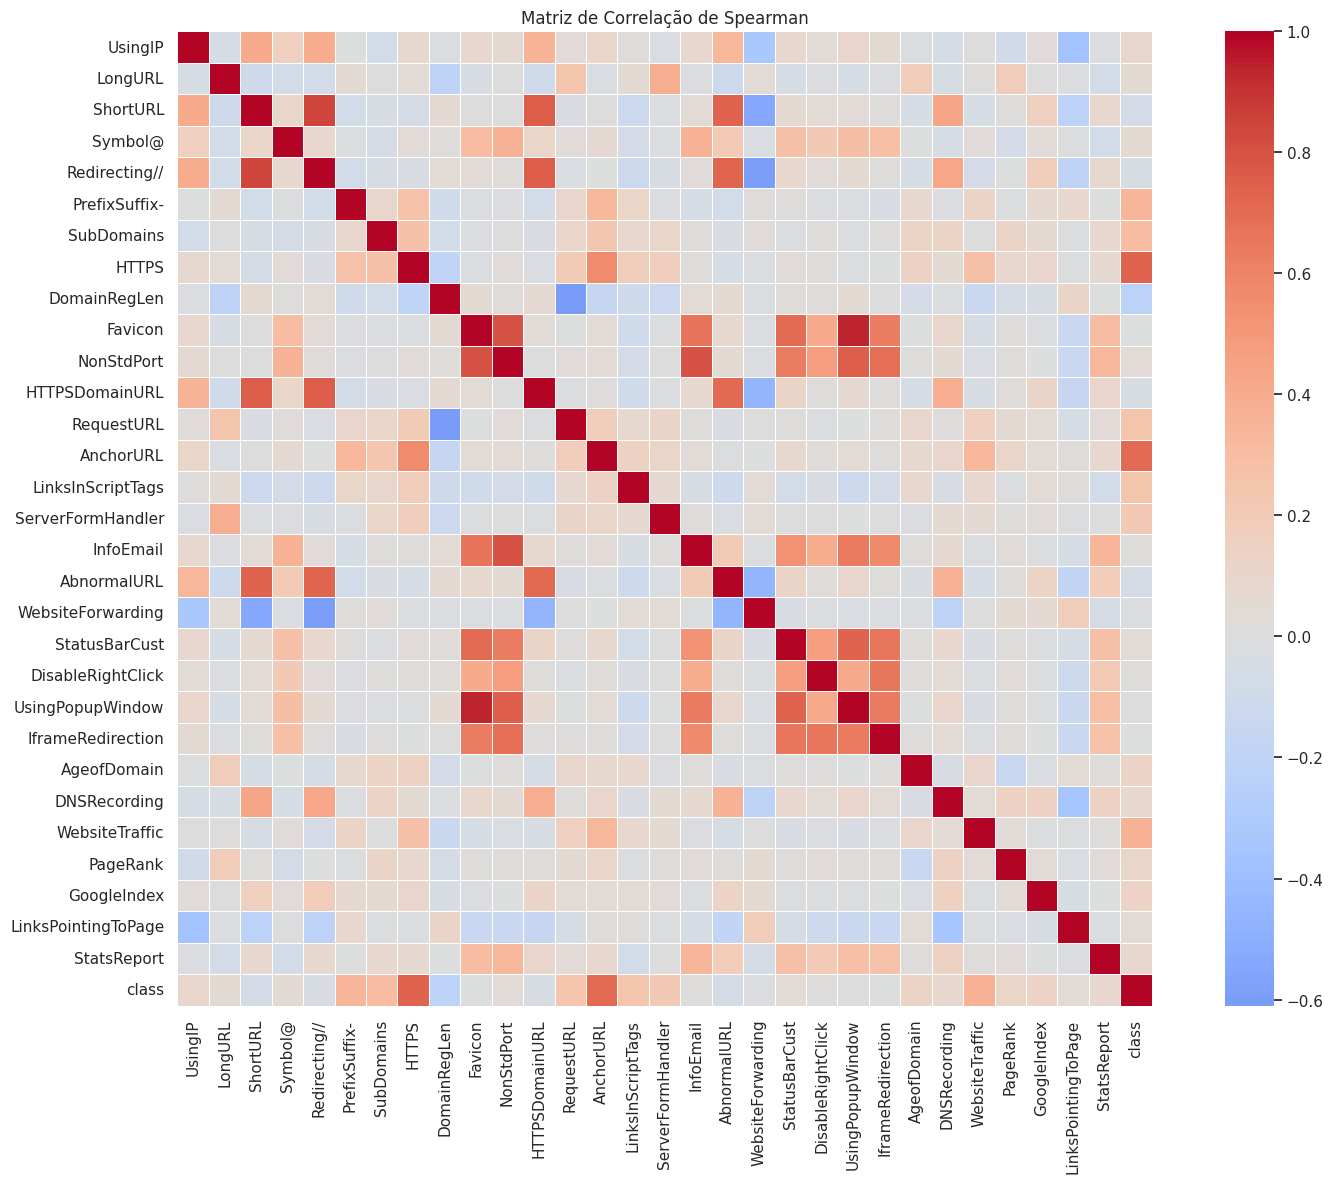

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
UsingIP,1.000000,-0.053328,0.403547,0.158766,0.397220,-0.005306,-0.079224,0.075083,-0.022830,0.087093,...,0.096953,0.054739,-0.010580,-0.050929,0.004148,-0.091857,0.029206,-0.365381,-0.019420,0.094033
LongURL,-0.053328,1.000000,-0.104024,-0.079167,-0.078412,0.050814,0.002255,0.043399,-0.216462,-0.041320,...,-0.050905,-0.014403,0.175516,-0.040843,0.011847,0.181149,0.002116,-0.013769,-0.070759,0.053557
ShortURL,0.403547,-0.104024,1.000000,0.104433,0.843149,-0.080458,-0.041750,-0.060335,0.060950,0.006084,...,0.036599,0.016570,-0.052562,0.436163,-0.051237,0.014612,0.155832,-0.222104,0.085572,-0.067931
Symbol@,0.158766,-0.079167,0.104433,1.000000,0.087086,-0.011711,-0.058570,0.034167,0.015549,0.304887,...,0.290880,0.284401,-0.005459,-0.047820,0.030122,-0.064714,0.037047,-0.011905,-0.080286,0.052994
Redirecting//,0.397220,-0.078412,0.843149,0.087086,1.000000,-0.085709,-0.043270,-0.035822,0.047314,0.035223,...,0.054595,0.010536,-0.050374,0.431235,-0.067973,-0.003272,0.178565,-0.218941,0.069849,-0.038885
PrefixSuffix-,-0.005306,0.050814,-0.080458,-0.011711,-0.085709,1.000000,0.090547,0.268922,-0.096826,-0.007487,...,-0.014716,-0.036894,0.074083,-0.016610,0.121091,-0.006855,0.067796,0.075830,-0.002851,0.348588
SubDomains,-0.079224,0.002255,-0.041750,-0.058570,-0.043270,0.090547,1.000000,0.271957,-0.084706,-0.016504,...,-0.024915,0.010754,0.123820,0.125335,0.000595,0.119045,0.057596,-0.007042,0.082553,0.304612
HTTPS,0.075083,0.043399,-0.060335,0.034167,-0.035822,0.268922,0.271957,1.000000,-0.198042,-0.013103,...,-0.011156,-0.005092,0.149643,0.052389,0.278811,0.080374,0.097179,-0.006776,0.065030,0.735788
DomainRegLen,-0.022830,-0.216462,0.060950,0.015549,0.047314,-0.096826,-0.084706,-0.198042,1.000000,0.054286,...,0.051443,0.004414,-0.062924,-0.010573,-0.133464,-0.059938,-0.039741,0.114470,-0.002371,-0.225879
Favicon,0.087093,-0.041320,0.006084,0.304887,0.035223,-0.007487,-0.016504,-0.013103,0.054286,1.000000,...,0.939632,0.627603,-0.002582,0.088285,-0.045532,0.011725,-0.016685,-0.139325,0.301111,-0.000231


In [18]:
matriz_correlacao(df, method="spearman", target="class", drop_cols=["Index"])

## 18. Pares de features altamente correlacionadas

In [19]:
pares_altamente_correlacionados(df, threshold=0.80, method="pearson", target="class", drop_cols=["Index"])

PARES DE FEATURES COM |CORRELAÇÃO| >= 0.8 (pearson)
  Redirecting// <-> ShortURL: 0.8431
  NonStdPort <-> Favicon: 0.8038
  UsingPopupWindow <-> Favicon: 0.9396


## 19. Desequilíbrio de categorias por feature

Identifica a categoria dominante de cada feature e a respetiva percentagem.

In [20]:
desequilibrio_categorias(df, target="class", drop_cols=["Index"])

DESEQUILÍBRIO DE CATEGORIAS POR FEATURE
  UsingIP: categoria dominante = 1 (65.7% dos registos)
  LongURL: categoria dominante = -1 (81.1% dos registos)
  ShortURL: categoria dominante = 1 (86.9% dos registos)
  Symbol@: categoria dominante = 1 (85.0% dos registos)
  Redirecting//: categoria dominante = 1 (87.1% dos registos)
  PrefixSuffix-: categoria dominante = -1 (86.7% dos registos)
  SubDomains: categoria dominante = 1 (36.8% dos registos)
  HTTPS: categoria dominante = 1 (57.3% dos registos)
  DomainRegLen: categoria dominante = -1 (66.8% dos registos)
  Favicon: categoria dominante = 1 (81.4% dos registos)
  NonStdPort: categoria dominante = 1 (86.4% dos registos)
  HTTPSDomainURL: categoria dominante = 1 (83.8% dos registos)
  RequestURL: categoria dominante = 1 (59.3% dos registos)
  AnchorURL: categoria dominante = 0 (48.3% dos registos)
  LinksInScriptTags: categoria dominante = 0 (40.2% dos registos)
  ServerFormHandler: categoria dominante = -1 (76.3% dos registos)
  Info

## 20. Conclusões da EDA

- O dataset tem **11.054 registos** e **32 colunas** (Index + 30 features + class).
- **Sem valores em falta** e **sem duplicados completos** no dataset original.
- Distribuição relativamente equilibrada: **55,7% legítimos** e **44,3% phishing**.
- Todas as features são do tipo `int64`, codificadas em **-1, 0, 1** (exceto `WebsiteForwarding` que usa 0 e 1).
- **Sem variáveis constantes** — todas as 30 features têm pelo menos 2 valores distintos.
- Features com maior correlação com a classe: **HTTPS (0,71)**, **AnchorURL (0,69)**, **PrefixSuffix- (0,35)**, **WebsiteTraffic (0,35)**.
- Features com correlação muito baixa: **Favicon**, **UsingPopupWindow**, **IframeRedirection**, **StatusBarCust** (candidatas a feature selection).
- 3 pares de features com correlação >= 0,80: **Favicon/UsingPopupWindow (0,93)**, **ShortURL/Redirecting// (0,81)**, **Favicon/NonStdPort (0,81)**.
- A coluna **Index** deve ser removida por não ser preditiva.